In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.integrate import solve_ivp

In [8]:
gamma = 42.58e6 * 2 * np.pi            # in rad/(s*T)
M0 = np.array([0,0,1])

T_1 = 100           # 1400e-3
T_2 = 100           # 25e-3

In [33]:
# Amplitudenmdoulation und Phasenmodulation

def B1x(t, A0, T_half):
    beta = 6 / T_half
    B1_ampl = A0 / np.cosh(beta * t)
    return B1_ampl

def delta_omega(t, T_half, sweep_bb):
    beta = 6 / T_half
    mu = sweep_bb * np.pi / (beta * np.tanh(beta * T_half))
    frequency_mod_rad = - mu * beta * np.tanh(beta * t)
    return frequency_mod_rad

# Bloch-Gleichung

def bloch_rot(t, M, A0, T_half, sweep_bb, T_1, T_2):
    beta = 6 / T_half 
    mu = sweep_bb * np.pi / (beta * np.tanh(beta * T_half)) 
    B1_x = B1x(t, A0, T_half)
    B1_z = delta_omega(t, T_half, sweep_bb) / gamma
    B1_vec = np.array([B1_x, 0, B1_z])
    dMdt = gamma * np.cross(M, B1_vec) + 1/T_1 * (M0 - np.array([0,0,M[2]])) - 1/T_2 * (np.array([M[0],M[1],0]))
    return dMdt

# Adiabatische Bedingung: << 1

def adiabatic(A0, T_half, sweep_bb):
    beta = 6 / T_half 
    mu = sweep_bb * np.pi / (beta * np.tanh(beta * T_half))
    epsilon = (np.sqrt(mu) * beta) / (gamma * A0)
    return epsilon

Vor jeder Variation immer einmal Puls Parameter ausführen!

In [97]:
# Puls Parameter

A0 = 8e-6 
T_half = 7e-3                      # Achtung: Das ist die halbe Pulsdauer!
sweep_bb = 300                    # in Hz

t_start = - T_half
t_end = T_half
times = np.linspace(t_start, t_end, 2000)

print("Adiabatischer Faktor:", adiabatic(A0, T_half, sweep_bb))

Adiabatischer Faktor: 0.4199420121644274


In [66]:
# Berechnung Amplitude und Phase

time_values = times
amp_values = np.array([B1x(t, A0, T_half) for t in times])
frequency_values_rad = np.array([delta_omega(t, T_half, sweep_bb) for t in times])
frequency_values_hz = frequency_values_rad / (2* np.pi)

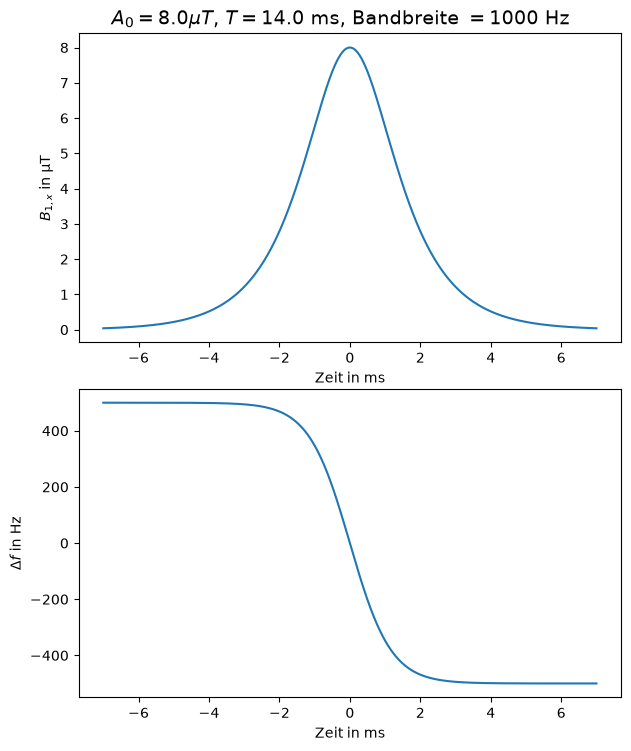

In [67]:
# Amplitude und Frequenz plotten

fig, ax = plt.subplots(2,1, figsize=(7,8))
fig.suptitle(f"$A_0 = {A0*1e6} µT$, $T = {2*T_half*1e3}$ ms, Bandbreite $= {sweep_bb}$ Hz", 
              fontsize = 14, y=0.96)
fig.subplots_adjust(top=0.93, bottom=0.10, hspace=0.15)

ax[0].plot(time_values*1e3, amp_values*1e6)
ax[0].set_xlabel("Zeit in ms")
ax[0].set_ylabel("$B_{1,x}$ in µT")

ax[1].plot(time_values*1e3, frequency_values_hz)
ax[1].set_xlabel("Zeit in ms")
ax[1].set_ylabel(r"$\Delta f$ in Hz")

plt.show()

In [68]:
# Bloch-Gleichung lösen

solution = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0, T_half, sweep_bb, T_1, T_2), t_eval = time_values)
Mx = solution.y[0]
My = solution.y[1]
Mz = solution.y[2]

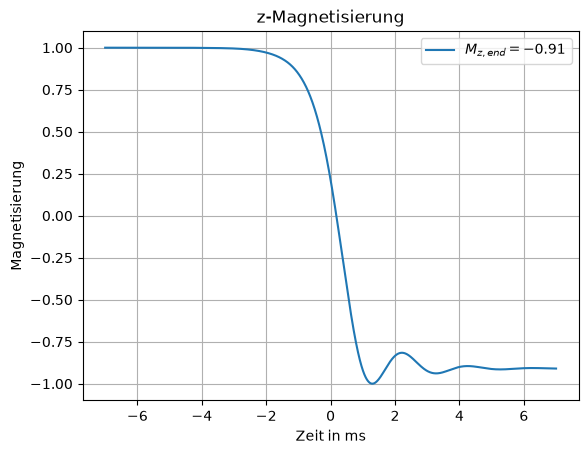

In [69]:
# Magnetisierung plotten

last_times = int(0.05 * len(times))
inversionsgrad = np.mean(Mz[-last_times:])

plt.figure()

plt.plot(times * 1e3, Mz, label = fr"$M_{{z,end}} = {inversionsgrad:.2}$")

plt.xlabel("Zeit in ms")
plt.ylabel("Magnetisierung")
plt.ylim(-1.1,1.1)
plt.grid(True)
plt.title("z-Magnetisierung")
plt.legend()
plt.show()

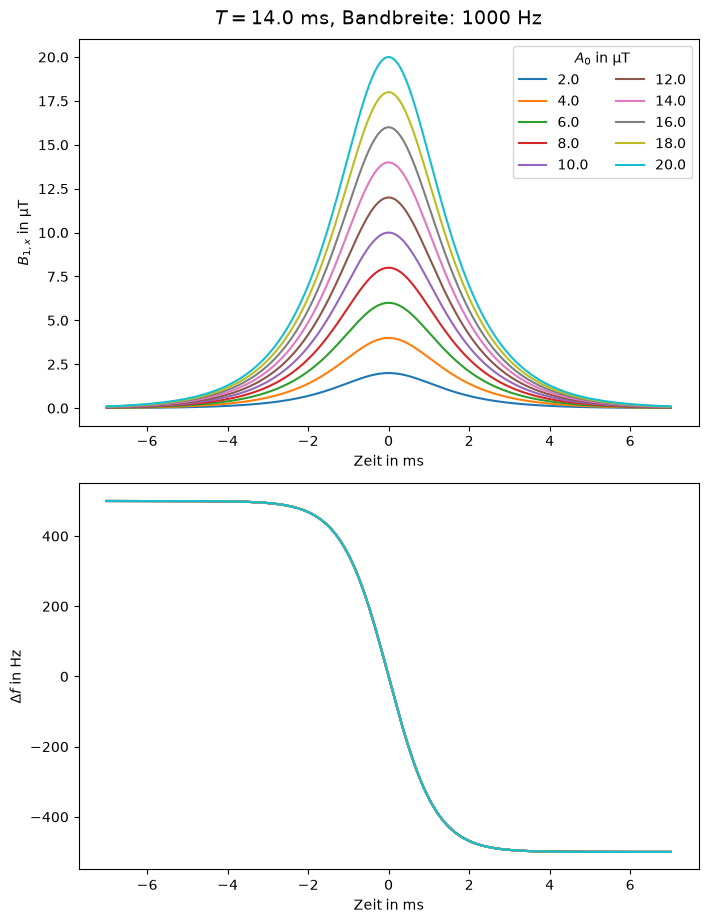

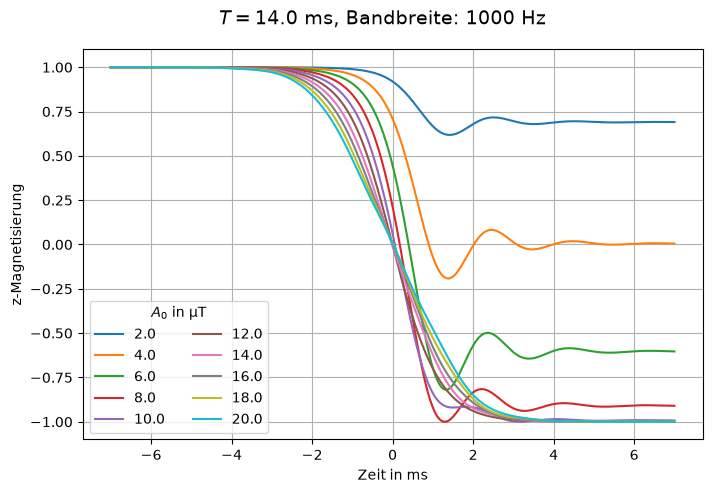

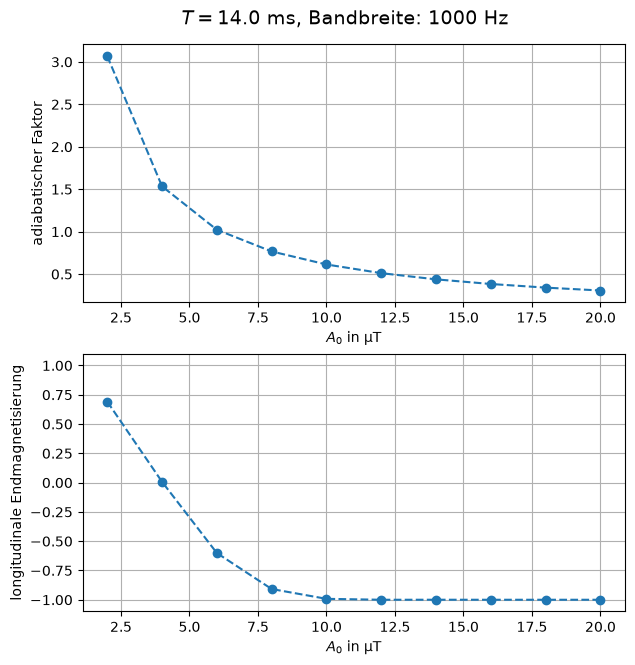

In [70]:
# Variation A0

A0_range = np.linspace(2e-6, 20e-6, 10)

epsilons = []
inversionsgrade = []

fig1, ax1 = plt.subplots(2,1, figsize=(8,10))
fig1.suptitle(f"$T = {2*T_half*1e3}$ ms, Bandbreite: {sweep_bb} Hz", fontsize = 14, y=0.96)
fig1.subplots_adjust(top=0.93, bottom=0.10, hspace=0.15)

fig3, ax3 = plt.subplots(1,1, figsize=(8,5))
fig3.suptitle(f"$T = {2*T_half*1e3}$ ms, Bandbreite: {sweep_bb} Hz", fontsize = 14, y=0.96)
fig3.subplots_adjust(top=0.88, bottom=0.10, hspace=0.2)

for A0_value in A0_range:
    
    amp_values = np.array([B1x(t, A0_value, T_half) for t in times])
    frequency_values_rad = np.array([delta_omega(t, T_half, sweep_bb) for t in times])
    frequency_values_hz = frequency_values_rad / (2 * np.pi)

    ax1[0].plot(times*1e3, amp_values*1e6, label = f"{A0_value*1e6:.1f}")
    ax1[0].legend(title = r"$A_0$ in µT", ncol=2)
    ax1[0].set_xlabel("Zeit in ms")
    ax1[0].set_ylabel(r"$B_{1,x}$ in µT")

    ax1[1].plot(times*1e3, frequency_values_hz)
    ax1[1].set_xlabel("Zeit in ms")
    ax1[1].set_ylabel(r"$\Delta f$ in Hz")


    solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0_value, T_half, sweep_bb, T_1, T_2), t_eval = time_values)
    Mzs = solutions.y[2]

    ax3.plot(times*1e3, Mzs, label = f"{A0_value*1e6:.1f}")
    ax3.legend(title = r"$A_0$ in µT", ncol=2)
    ax3.set_xlabel("Zeit in ms")
    ax3.set_ylabel("z-Magnetisierung")
    ax3.grid(True)
    ax3.set_ylim(-1.1, 1.1)


    last_times = int(0.05 * len(times))
    inversionsgrad = np.mean(Mzs[-last_times:])
    inversionsgrade.append(inversionsgrad)
    
    epsilon = adiabatic(A0_value, T_half, sweep_bb)
    epsilons.append(epsilon)
    

fig2, ax2 = plt.subplots(2,1, figsize=(7,7))
fig2.suptitle(f"$T = {2*T_half*1e3}$ ms, Bandbreite: {sweep_bb} Hz", fontsize = 14, y=0.96)
fig2.subplots_adjust(top=0.91, bottom=0.10, hspace=0.2)

ax2[0].plot(A0_range*1e6, epsilons, "o--")
ax2[0].set_xlabel(r"$A_0$ in µT")
ax2[0].set_ylabel("adiabatischer Faktor")
ax2[0].grid(True)

ax2[1].plot(A0_range*1e6, inversionsgrade, "o--")
ax2[1].set_xlabel(r"$A_0$ in µT")
ax2[1].set_ylabel("longitudinale Endmagnetisierung")
ax2[1].grid(True)
ax2[1].set_ylim(-1.1, 1.1)
ax2[1].yaxis.set_major_locator(MultipleLocator(0.25))

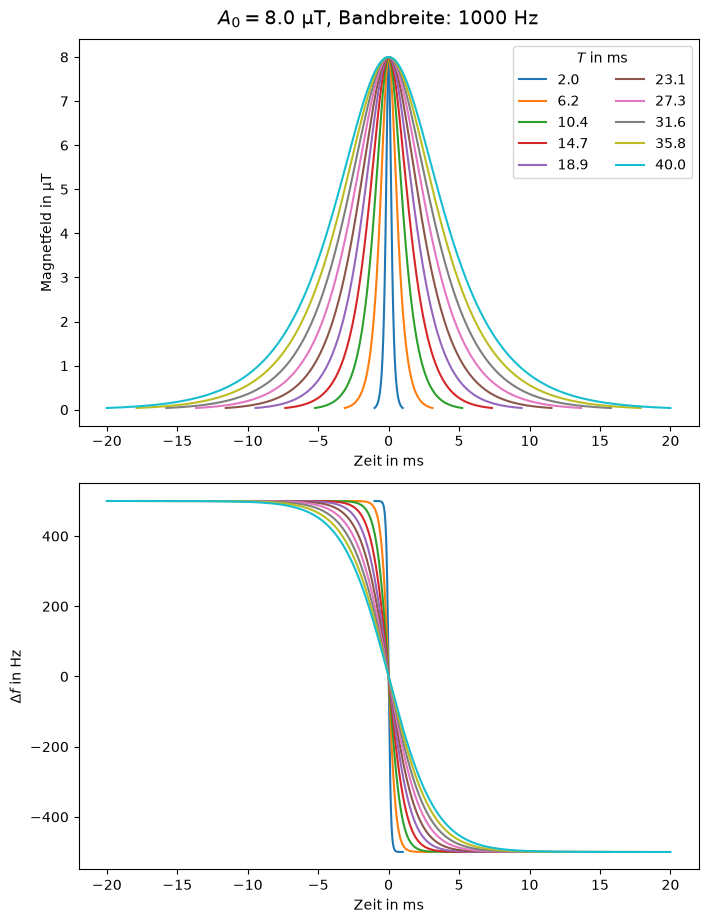

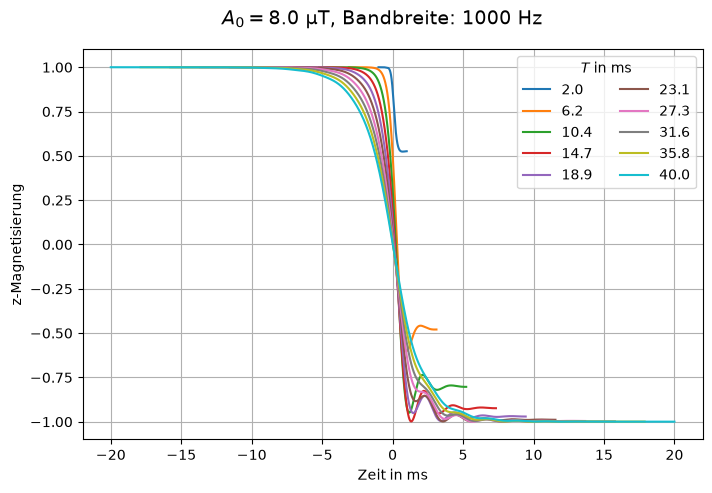

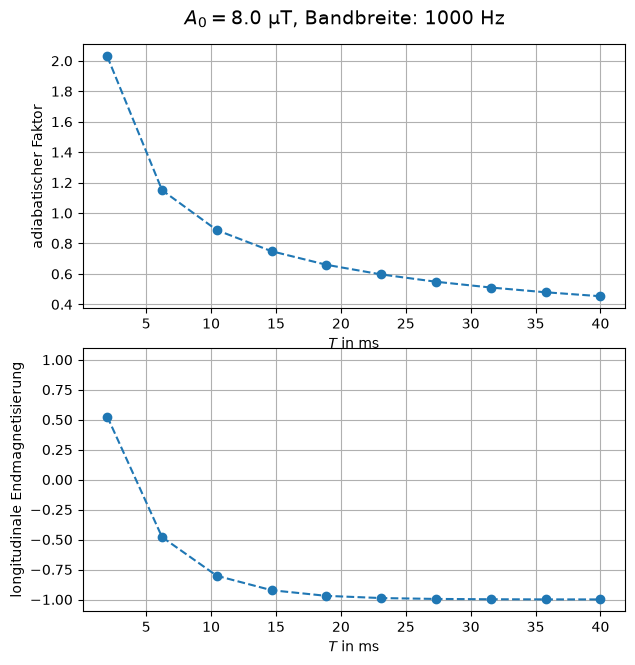

In [72]:
# Variation T

T_range = np.linspace(1e-3, 20e-3, 10)

epsilons = []
inversionsgrade = []

fig1, ax1 = plt.subplots(2,1, figsize=(8,10))
fig1.suptitle(f"$A_0 = {A0*1e6}$ µT, Bandbreite: {sweep_bb} Hz", fontsize = 14, y=0.96)
fig1.subplots_adjust(top=0.93, bottom=0.10, hspace=0.15)

fig3, ax3 = plt.subplots(1,1, figsize=(8,5))
fig3.suptitle(f"$A_0 = {A0*1e6}$ µT, Bandbreite: {sweep_bb} Hz", fontsize = 14, y=0.96)
fig3.subplots_adjust(top=0.88, bottom=0.10, hspace=0.2)

for T_value in T_range:

    t_start = - T_value
    t_end = T_value
    times = np.linspace(t_start, t_end, 2000)

    amp_values = np.array([B1x(t, A0, T_value) for t in times])
    frequency_values_rad = np.array([delta_omega(t, T_value, sweep_bb) for t in times])
    frequency_values_hz = frequency_values_rad / (2 * np.pi)

    ax1[0].plot(times*1e3, amp_values*1e6, label = f"{2*T_value*1e3:.1f}")
    ax1[0].legend(title = r"$T$ in ms", ncol=2)
    ax1[0].set_xlabel("Zeit in ms")
    ax1[0].set_ylabel("Magnetfeld in µT")

    ax1[1].plot(times*1e3, frequency_values_hz, label = f"{2*T_value*1e3:.1f}")
    ax1[0].legend(title = r"$T$ in ms", ncol=2)
    ax1[1].set_xlabel("Zeit in ms")
    ax1[1].set_ylabel(r"$\Delta f$ in Hz")


    solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0, T_value, sweep_bb, T_1, T_2), t_eval = times)
    Mzs = solutions.y[2]
    
    ax3.plot(times*1e3, Mzs, label = f"{2*T_value*1e3:.1f}")
    ax3.legend(title = r"$T$ in ms", ncol=2)
    ax3.set_xlabel("Zeit in ms")
    ax3.set_ylabel("z-Magnetisierung")
    ax3.grid(True)
    ax3.set_ylim(-1.1, 1.1)


    last_times = int(0.05 * len(times))
    inversionsgrad = np.mean(Mzs[-last_times:])
    inversionsgrade.append(inversionsgrad)

    epsilon = adiabatic(A0, T_value, sweep_bb)
    epsilons.append(epsilon)

    
fig2, ax2 = plt.subplots(2,1, figsize=(7,7))
fig2.suptitle(f"$A_0 = {A0*1e6}$ µT, Bandbreite: {sweep_bb} Hz", fontsize = 14, y=0.96)
fig2.subplots_adjust(top=0.91, bottom=0.10, hspace=0.15)

ax2[0].plot(2*T_range*1e3, epsilons, "o--")
ax2[0].set_xlabel(r"$T$ in ms")
ax2[0].set_ylabel("adiabatischer Faktor")
ax2[0].grid(True)

ax2[1].plot(2*T_range*1e3, inversionsgrade, "o--")
ax2[1].set_xlabel(r"$T$ in ms")
ax2[1].set_ylabel("longitudinale Endmagnetisierung")
ax2[1].grid(True)
ax2[1].set_ylim(-1.1, 1.1)
ax2[1].yaxis.set_major_locator(MultipleLocator(0.25))    

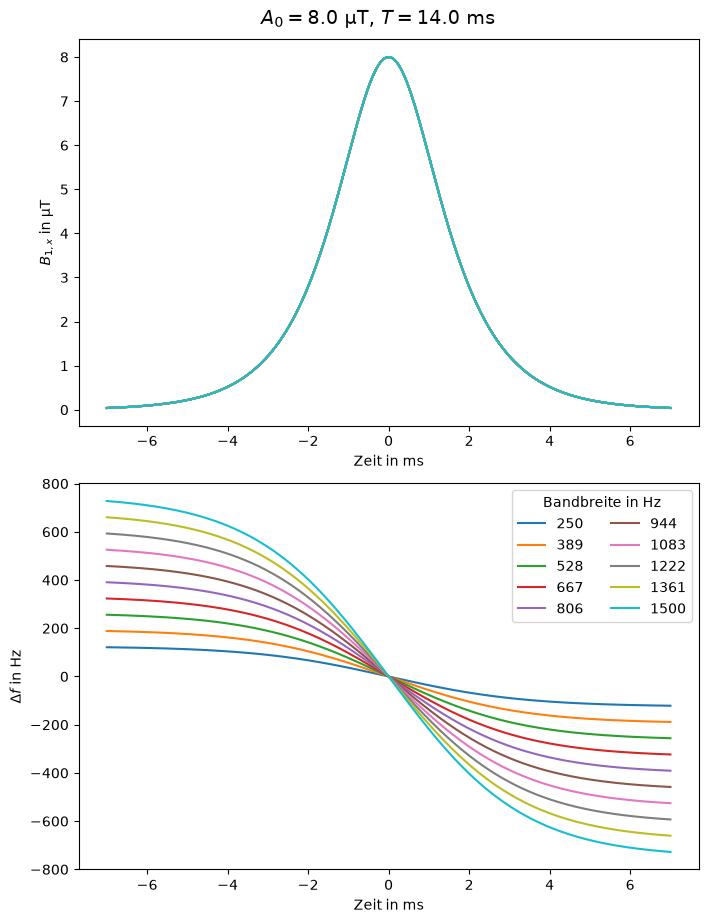

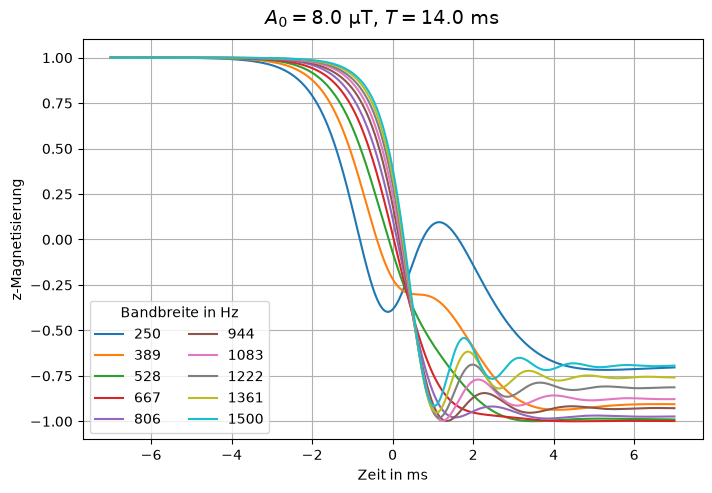

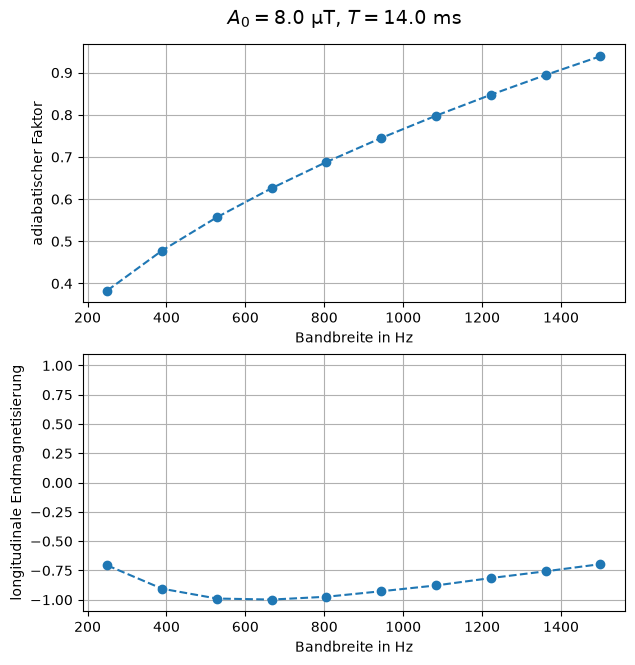

In [64]:
# Variation sweep

sweep_range = np.linspace(250, 1500, 10)

epsilons = []
inversionsgrade = []

fig1, ax1 = plt.subplots(2,1, figsize=(8,10))
fig1.suptitle(f"$A_0 = {A0*1e6}$ µT, $T = {2*T_half*1e3}$ ms", fontsize = 14, y=0.96)
fig1.subplots_adjust(top=0.93, bottom=0.10, hspace=0.15)

fig3, ax3 = plt.subplots(1,1, figsize=(8,5))
fig3.suptitle(f"$A_0 = {A0*1e6}$ µT, $T = {2*T_half*1e3}$ ms", fontsize = 14, y=0.96)
fig3.subplots_adjust(top=0.9, bottom=0.10, hspace=0.2)

for sweep_value in sweep_range:
    
    amp_values = np.array([B1x(t, A0, T_half) for t in times])
    frequency_values_rad = np.array([delta_omega(t, T_value, sweep_value) for t in times])
    frequency_values_hz = frequency_values_rad / (2 * np.pi)

    ax1[0].plot(times*1e3, amp_values*1e6)
    ax1[0].set_xlabel("Zeit in ms")
    ax1[0].set_ylabel(r"$B_{1,x}$ in µT")

    ax1[1].plot(times*1e3, frequency_values_hz, label = f"{sweep_value:.0f}")
    ax1[1].legend(title = "Bandbreite in Hz", ncol=2)
    ax1[1].set_xlabel("Zeit in ms")
    ax1[1].set_ylabel(r"$\Delta f$ in Hz")


    solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0, T_half, sweep_value, T_1, T_2), t_eval = time_values)
    Mzs = solutions.y[2]

    ax3.plot(times*1e3, Mzs, label = f"{sweep_value:.0f}")
    ax3.legend(title = r"Bandbreite in Hz", ncol=2, loc="lower left")
    ax3.set_xlabel("Zeit in ms")
    ax3.set_ylabel("z-Magnetisierung")
    ax3.grid(True)
    ax3.set_ylim(-1.1, 1.1)
    

    last_times = int(0.05 * len(times))
    inversionsgrad = np.mean(Mzs[-last_times:])
    inversionsgrade.append(inversionsgrad)

    epsilon = adiabatic(A0, T_half, sweep_value)
    epsilons.append(epsilon)


fig2, ax2 = plt.subplots(2,1, figsize=(7,7))
fig2.suptitle(f"$A_0 = {A0*1e6}$ µT, $T = {2*T_half*1e3}$ ms", fontsize = 14, y=0.96)
fig2.subplots_adjust(top=0.91, bottom=0.10, hspace=0.2)

ax2[0].plot(sweep_range, epsilons, "o--")
ax2[0].set_xlabel(r"Bandbreite in Hz")
ax2[0].set_ylabel("adiabatischer Faktor")
ax2[0].grid(True)

ax2[1].plot(sweep_range, inversionsgrade, "o--")
ax2[1].set_xlabel(r"Bandbreite in Hz")
ax2[1].set_ylabel("longitudinale Endmagnetisierung")
ax2[1].grid(True)
ax2[1].set_ylim(-1.1, 1.1)
ax2[1].yaxis.set_major_locator(MultipleLocator(0.25))


C:\Users\schuma12\AppData\Local\Temp\1\ipykernel_17704\2884685952.py:19: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(1,1, figsize=(5,3))


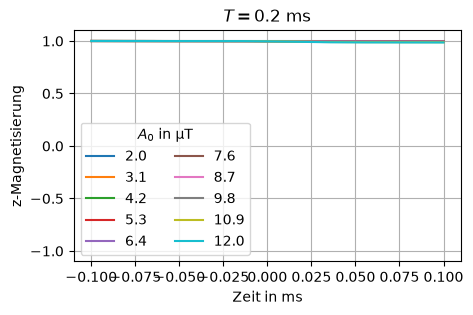

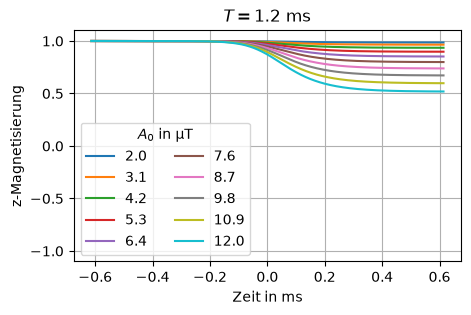

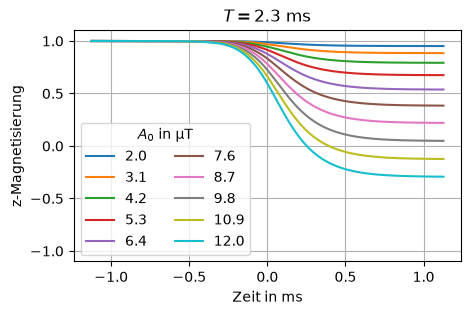

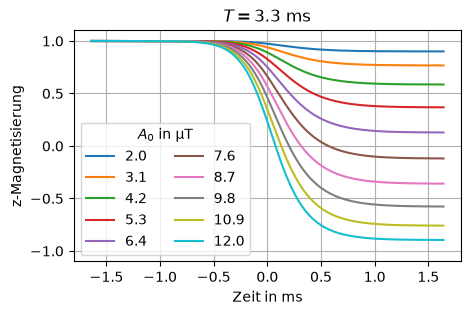

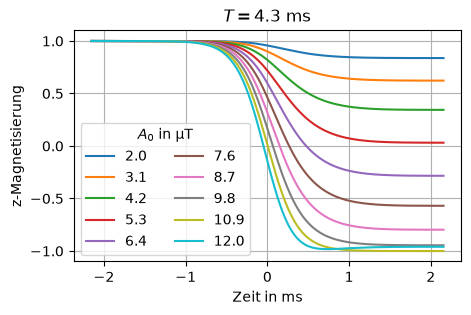

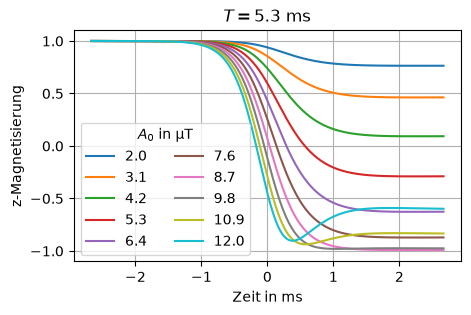

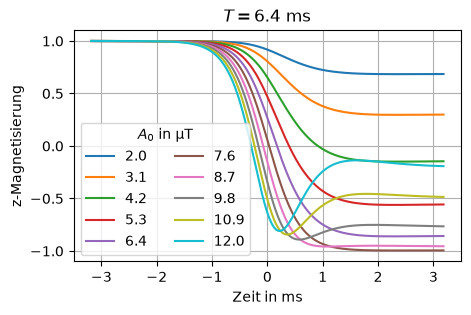

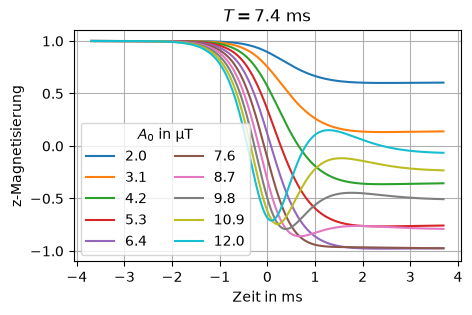

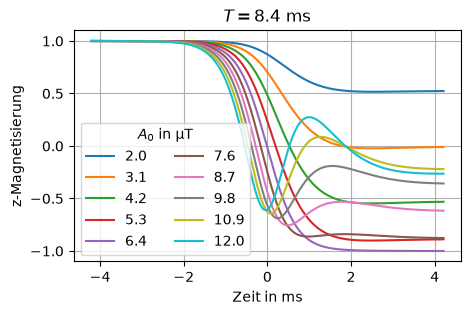

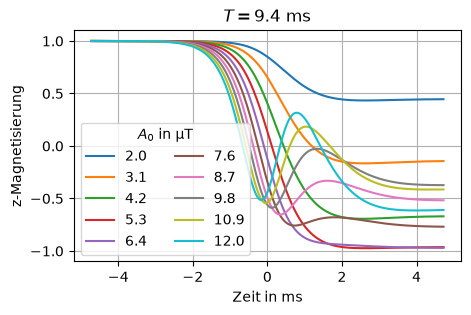

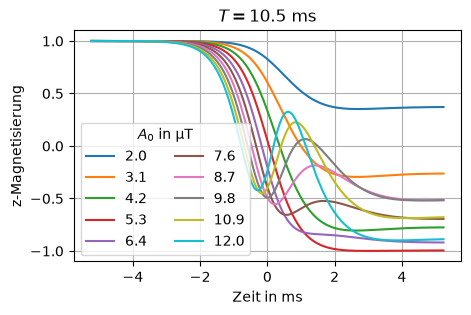

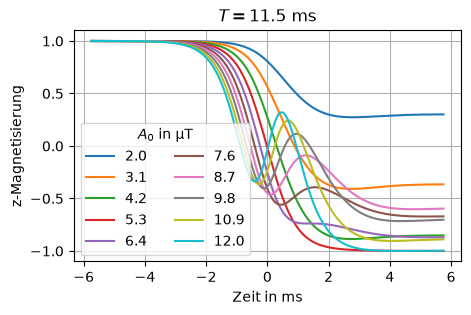

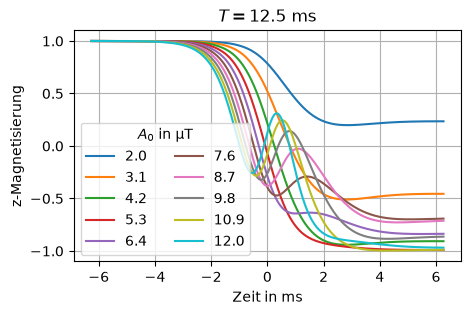

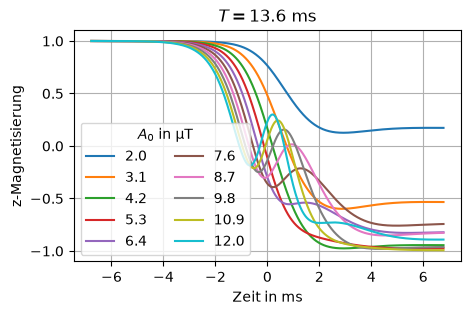

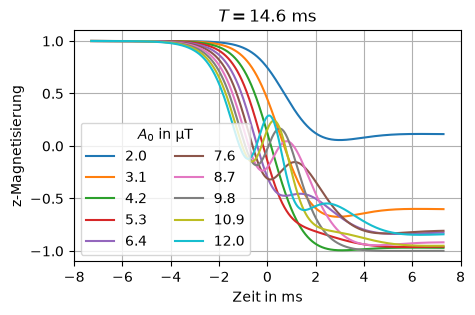

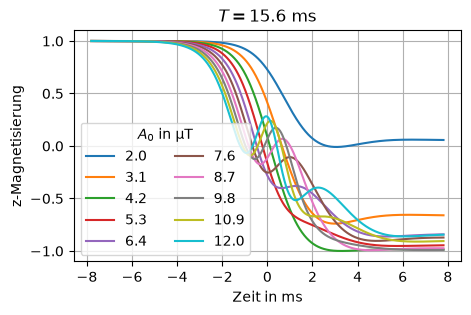

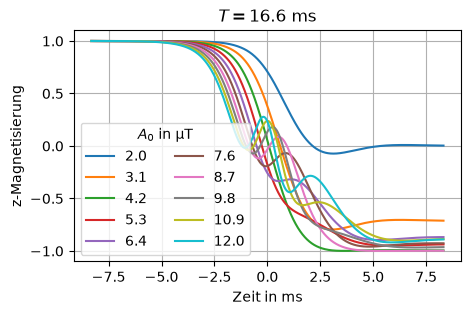

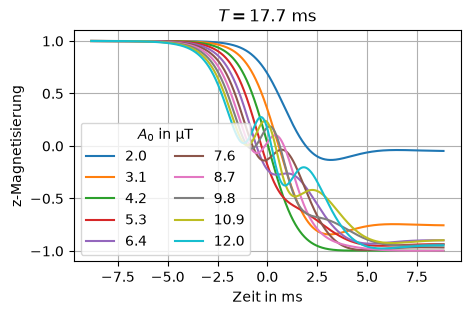

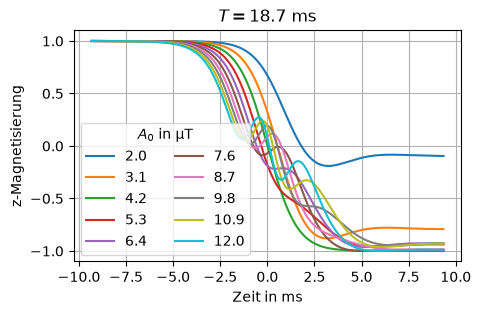

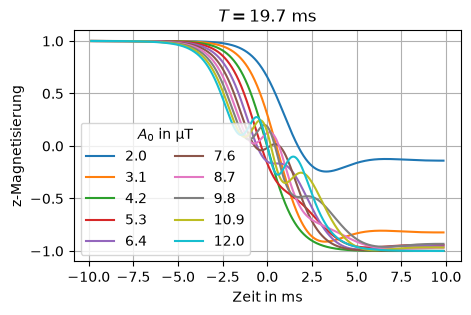

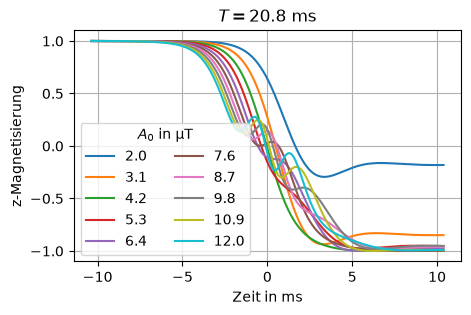

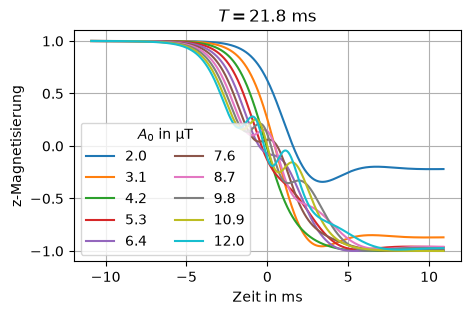

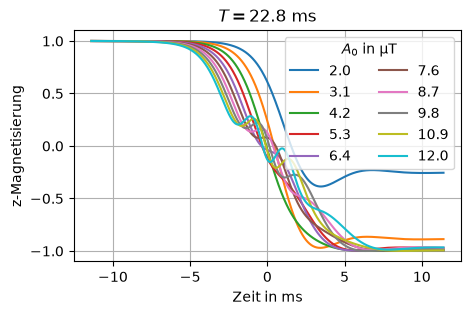

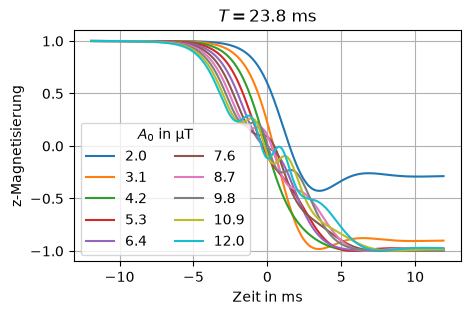

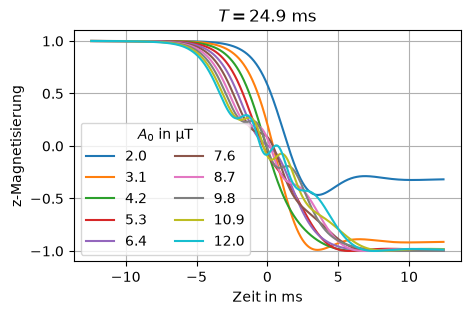

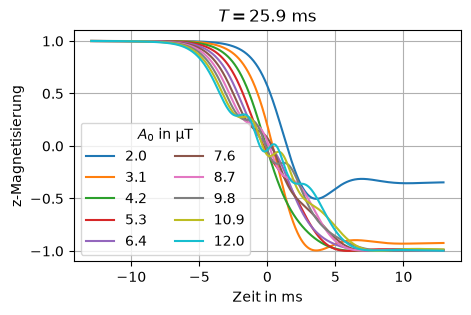

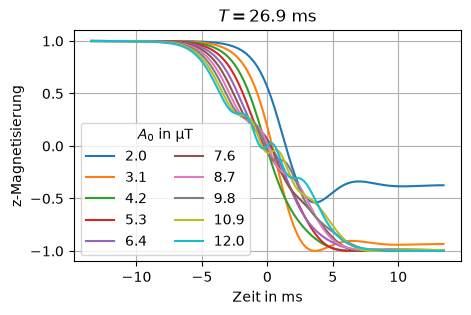

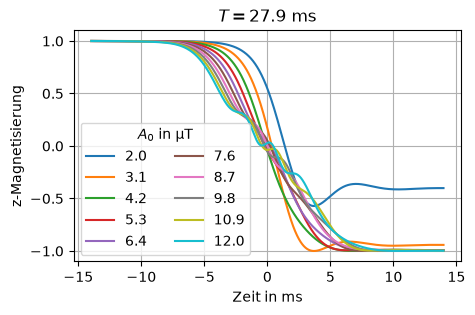

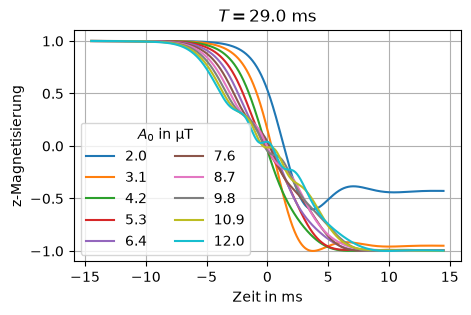

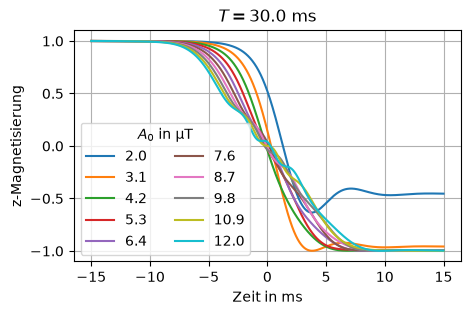

In [101]:
# Variation A0 und T

T_range = np.linspace(0.1e-3, 15e-3, 30)
A0_range = np.linspace(2e-6, 12e-6, 10)

epsilons = []
inversionsgrade = []

for T_value in T_range:

    t_start = - T_value
    t_end = T_value
    times = np.linspace(t_start, t_end, 2000)

    epsilons2 = []
    inversionsgrade2 = []
    winkels2 = []

    fig, ax = plt.subplots(1,1, figsize=(5,3))

    for A0_value in A0_range:

        epsilon = adiabatic(A0_value, T_value, sweep_bb)
        epsilons2.append(epsilon)

        solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0_value, T_value, sweep_bb, T_1, T_2), t_eval = times)
        Mzs = solutions.y[2]

        last_times = int(0.05 * len(times))
        inversionsgrad = np.mean(Mzs[-last_times:])
        # inversionsgrad = Mzs[-1]
        inversionsgrade2.append(inversionsgrad)

        ax.plot(times*1e3, Mzs, label = f"{A0_value*1e6:.1f}")
        ax.legend(title = r"$A_0$ in µT", ncol=2)
        ax.set_xlabel("Zeit in ms")
        ax.set_ylabel("z-Magnetisierung")
        ax.set_title(f"$T = {T_value*2e3:.1f}$ ms")
        ax.grid(True)
        ax.set_ylim(-1.1, 1.1)

    epsilons.append(epsilons2)
    inversionsgrade.append(inversionsgrade2)  

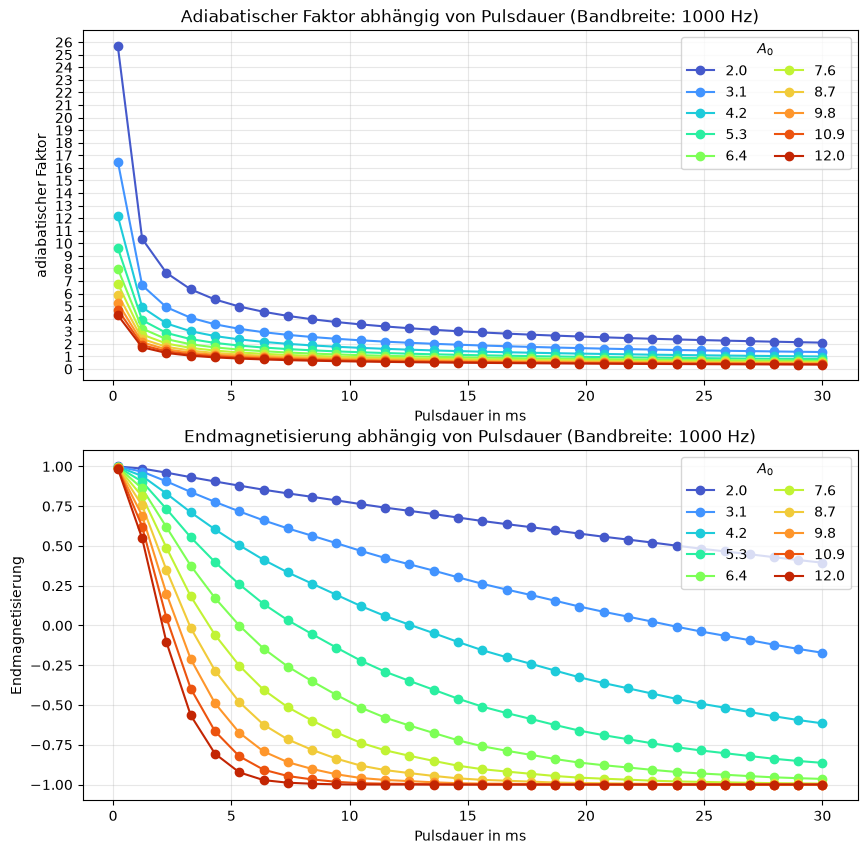

In [96]:
fig, ax = plt.subplots(2,1, figsize=(10,10))

colors = plt.cm.turbo(np.linspace(0.1, 0.9, len(A0_range)))

for i, A0_value in enumerate(A0_range):
    ax[0].plot(2*T_range*1e3, np.array(epsilons)[:,i], "-o", color=colors[i], label=f"{A0_value*1e6:.1f}")

ax[0].set_xlabel("Pulsdauer in ms")
ax[0].set_ylabel("adiabatischer Faktor")
ax[0].set_title(f"Adiabatischer Faktor abhängig von Pulsdauer (Bandbreite: {sweep_bb} Hz)")
ax[0].grid(True, alpha=0.3)
ax[0].legend(title=r"$A_0$", ncol=2)
ax[0].yaxis.set_major_locator(MultipleLocator(1))

for i, A0_value in enumerate(A0_range):
    ax[1].plot(2*T_range*1e3, np.array(inversionsgrade)[:,i], "-o", color=colors[i], label=f"{A0_value*1e6:.1f}")

ax[1].set_xlabel("Pulsdauer in ms")
ax[1].set_ylabel("Endmagnetisierung")
ax[1].set_title(f"Endmagnetisierung abhängig von Pulsdauer (Bandbreite: {sweep_bb} Hz)")
ax[1].set_ylim(-1.1, 1.1)
ax[1].grid(True, alpha=0.3)
ax[1].legend(title=r"$A_0$", ncol=2)


plt.show()